# 05 · Preparación de datos

**Términos que se usan en este notebook:** [log-retorno](../docs/entrega_1/glosario.md) (cambio porcentual diario expresado en logaritmo: `r = ln(precio_t / precio_{t-1})`), [σ (volatilidad)](../docs/entrega_1/glosario.md) (desviación estándar de los retornos diarios: cuánto se mueve el precio en un día típico), [σ20 y σ252](../docs/entrega_1/glosario.md) (la misma desviación medida en el último mes y en el último año bursátil), [look-ahead](../docs/entrega_1/glosario.md) (usar en t un dato que solo se conoce después de t), [etiqueta](../docs/entrega_1/glosario.md) (lo que el modelo debe predecir; es lo único que mira al futuro), [censura](../docs/entrega_1/glosario.md) (una fila cuyo futuro todavía no ocurrió: su etiqueta no se puede resolver), [z-score](../docs/entrega_1/glosario.md) (restar la media y dividir por la desviación para que las variables queden en la misma escala), [EPS TTM](../docs/entrega_1/glosario.md) (utilidad por acción de los últimos 12 meses), [P/E](../docs/entrega_1/glosario.md) (precio ÷ EPS) y [filed](../docs/entrega_1/glosario.md) (fecha en que la SEC publicó el dato).

**Objetivo.** Dejar listos los datos del modelo técnico y de la rama fundamental: cada transformación se muestra con su evidencia **antes y después** (filas, vacíos y filas de muestra), y cada gráfico lleva una lectura con cifras. Es la fase de **preparación de datos** de ASUM-DM.

**Punto del enunciado que cubre.** Punto 8 (preparación de datos). Lo que se construye aquí vive en funciones de `comunes.py` (`construir_panel_diario`, `etiqueta_entrada`, `tabla_modelo`, `asignar_conjunto`, `submuestra`) porque lo reutilizan los notebooks 06 a 08 y la API; este notebook ejecuta esas funciones y comprueba sus propiedades.

**Qué alimenta.** El notebook 06 (estrategia de validación), el 07 (modelos) y el 08 (simulación). Las cifras quedan en `data/resultados/nb05.json`.

**Contenido.** §1 carga (antes) · §2 variables (después) · §3 sin look-ahead · §4 calentamiento y huecos · §5 etiqueta y censura · §6 estandarización, codificación, submuestra y resumen de transformaciones · §7 rama fundamental · §8 balance y datos preparados · §9 calidad con las 9 dimensiones · §10 diagrama de bloques · §11 resultados.

In [1]:
import json, sys, warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from sklearn.preprocessing import StandardScaler
sys.path.insert(0, "."); import comunes as cm      # nbconvert ejecuta el kernel en notebooks/, donde está comunes.py
sns.set_theme(style="whitegrid"); pd.set_option("display.float_format", "{:.4f}".format)
pd.set_option("display.width", 220); pd.set_option("display.max_rows", 200); pd.set_option("display.max_columns", 30)

# Constantes del notebook. N, rejilla de k, σ, brecha y fechas de la partición viven en comunes.py (cm.<nombre>).
TICKER_EJ = "KO"                    # empresa que ilustra cada transformación
CORTE_LOOKAHEAD = "2015-12-31"      # corte de la prueba de "sin look-ahead" (§3)
FECHA_EJ_ETIQUETA = "2018-01-17"    # fecha que ilustra la etiqueta (§5); la misma que usa la figura del notebook 04 para una entrada
FIN_NB04 = "2018-12-31"             # nb04 §4.3–4.4 cuenta las filas hasta esta fecha
N_NB04, TASA_NB04 = 47_544, 0.1839  # salida de nb04 §4.3–4.4: filas con k = 1, no censuradas y con σ252, y su tasa de toque
N_MUESTRA = 8                       # filas de muestra de los datos preparados
fm = lambda n: f"{n:,}".replace(",", " ")   # miles con espacio, como en el texto
res = {}                            # cifras que se guardan en data/resultados/nb05.json
cm.DIR_ASSETS_E2.mkdir(parents=True, exist_ok=True)

## 1. Carga de datos (el **antes**)

Se carga `precios_diarios` de la instantánea fechada (`data/snapshots`). Trae 23 símbolos: las 21 empresas de la industria piloto más el SPY y el XLP, que son referencias de mercado y de sector y **no entran al modelo**. Por eso se filtra con `cm.tickers()` y se comprueba que queden exactamente 21.

In [2]:
precios_all = cm.cargar_snapshot("precios_diarios")
print(f"instantánea completa: {fm(precios_all.shape[0])} filas, {precios_all.ticker.nunique()} símbolos")
precios = precios_all[precios_all.ticker.isin(cm.tickers())].copy()       # fuera SPY y XLP
precios["fecha"] = precios["fecha"].astype("datetime64[ns]")
assert precios.ticker.nunique() == 21, "el universo del modelo debe tener 21 empresas"

print(f"\nANTES (precios de las 21 empresas): {fm(precios.shape[0])} filas × {precios.shape[1]} columnas {list(precios.columns)}")
print(f"rango de fechas: {precios.fecha.min().date()} a {precios.fecha.max().date()}  ·  tickers: {precios.ticker.nunique()}")
print("\nvacíos por columna:"); print(precios.isna().sum().to_string())
print("\ntipos:"); print(precios.dtypes.to_string())
print("\n3 filas de muestra:"); print(precios.sample(3, random_state=cm.SEMILLA).sort_values(["ticker", "fecha"]).to_string(index=False))
res["dimensiones"] = {"antes": {"filas": int(len(precios)), "columnas": list(precios.columns), "tickers": int(precios.ticker.nunique()),
                                "fecha_min": str(precios.fecha.min().date()), "fecha_max": str(precios.fecha.max().date())}}

instantánea completa: 102 902 filas, 23 símbolos

ANTES (precios de las 21 empresas): 93 954 filas × 4 columnas ['fecha', 'ticker', 'close', 'volume']
rango de fechas: 2009-01-02 a 2026-10-15  ·  tickers: 21

vacíos por columna:
fecha     0
ticker    0
close     0
volume    0

tipos:
fecha     datetime64[ns]
ticker               str
close            float64
volume             int64

3 filas de muestra:
     fecha ticker   close   volume
2009-04-29    GIS 13.6675  6299600
2014-11-25     KR 23.3799 10915800
2019-01-29     PG 77.2478  9769800


**Lectura.** El **antes** son 93 954 filas (21 empresas × 4 474 sesiones, del 2009-01-02 al 2026-10-15) con 4 columnas y **0 vacíos**; las 102 902 filas de la instantánea incluyen además el SPY y el XLP (8 948 filas = 2 × 4 474), que se descartan y dejan exactamente 21 tickers. Cero vacíos significa que el precio de cierre existe todos los días del calendario, no que el dato sea perfecto: la calidad de las fuentes se audita en el notebook 02 y la ausencia de huecos se vuelve a comprobar en §4.

## 2. Variables del modelo (el **después**)

`cm.construir_panel_diario` agrega, para cada empresa y cada día:

| Variable | Qué es | Por qué entra | ¿Entra al modelo? |
|---|---|---|---|
| `r` | log-retorno del día | materia prima de las demás | no: intermedia |
| `abs_r` = \|r\| | tamaño del movimiento de hoy, sin importar el signo | un día muy movido suele anticipar más movimiento | **sí** |
| `sigma20` | desviación de los últimos 20 retornos (un mes bursátil) | volatilidad reciente | no: intermedia (solo sirve para el cociente) |
| `sigma252` | desviación de los últimos 252 retornos (un año bursátil) | volatilidad "normal" de la empresa; también fija el ancho de las barreras de la etiqueta | **sí** |
| `sigma20_sigma252` | cociente de las dos | si el mes está más agitado (>1) o más calmado (<1) que lo habitual | **sí** |

**Las cuatro variables que entran al modelo** son `cm.VARIABLES` = `abs_r`, `sigma20_sigma252`, `sigma252` y **`k`** (la distancia del nivel, que no sale del panel sino de la rejilla de la etiqueta, §5). Son las tres variables de **magnitud** que dejó la selección de indicadores del notebook 04 (§5) más `k`. `r` (con signo) y `sigma20` (en nivel) son pasos intermedios: `r` es el insumo de todas las demás y `sigma20` ya está resumida en el cociente, que la compara con `sigma252`. El ticker tampoco es una variable (§6.2).

**Todas las ventanas miran solo hacia atrás** (`rolling` termina en t, sin `center` ni `shift(-)`), así que lo que se calcula en t usa precios con fecha ≤ t. Es el cambio de supuesto frente a datos independientes: las filas de un mismo día están correlacionadas con las de días vecinos (las ventanas se solapan), y por eso la decisión de los notebooks siguientes sale de bootstrap por bloques de fechas y no de un p-value clásico.

**Validación y prueba también miran hacia atrás.** Una fila de 2019 usa la σ252 de los 252 retornos anteriores (de 2018 y antes); eso es válido porque en t se conoce el pasado. No es fuga: lo único que mira al futuro es la etiqueta, y la brecha (§6.1) impide que la etiqueta de una fila de entrenamiento toque el conjunto siguiente.

In [3]:
panel = cm.construir_panel_diario(precios)
VARS_PANEL = ["r", "abs_r", "sigma20", "sigma252", "sigma20_sigma252"]
print(f"DESPUÉS (panel diario): {fm(panel.shape[0])} filas × {panel.shape[1]} columnas {list(panel.columns)}")
print("\nvacíos por columna (los primeros días de cada empresa no completan su ventana):")
print(panel.isna().sum().to_string())
print("\n3 filas de muestra (KO):")
print(panel[panel.ticker == TICKER_EJ].dropna().iloc[[0, 1500, -1]].to_string(index=False))
print("\nresumen de las 5 variables (filas con valor):"); print(panel[VARS_PANEL].describe().T[["count", "mean", "50%", "std", "min", "max"]].to_string())

DESPUÉS (panel diario): 93 954 filas × 8 columnas ['fecha', 'ticker', 'close', 'r', 'abs_r', 'sigma20', 'sigma252', 'sigma20_sigma252']

vacíos por columna (los primeros días de cada empresa no completan su ventana):
fecha                  0
ticker                 0
close                  0
r                     21
abs_r                 21
sigma20              420
sigma252            5292
sigma20_sigma252    5292

3 filas de muestra (KO):
     fecha ticker   close       r  abs_r  sigma20  sigma252  sigma20_sigma252
2010-01-04     KO 17.1032  0.0007 0.0007   0.0082    0.0141            0.5775
2015-12-17     KO 31.1556 -0.0080 0.0080   0.0109    0.0090            1.2128
2026-10-15     KO 92.0000  0.0024 0.0024   0.0102    0.0119            0.8573

resumen de las 5 variables (filas con valor):
                      count   mean    50%    std     min    max
r                93933.0000 0.0004 0.0006 0.0141 -0.2770 0.3165
abs_r            93933.0000 0.0095 0.0067 0.0104  0.0000 0.3165
sigma2

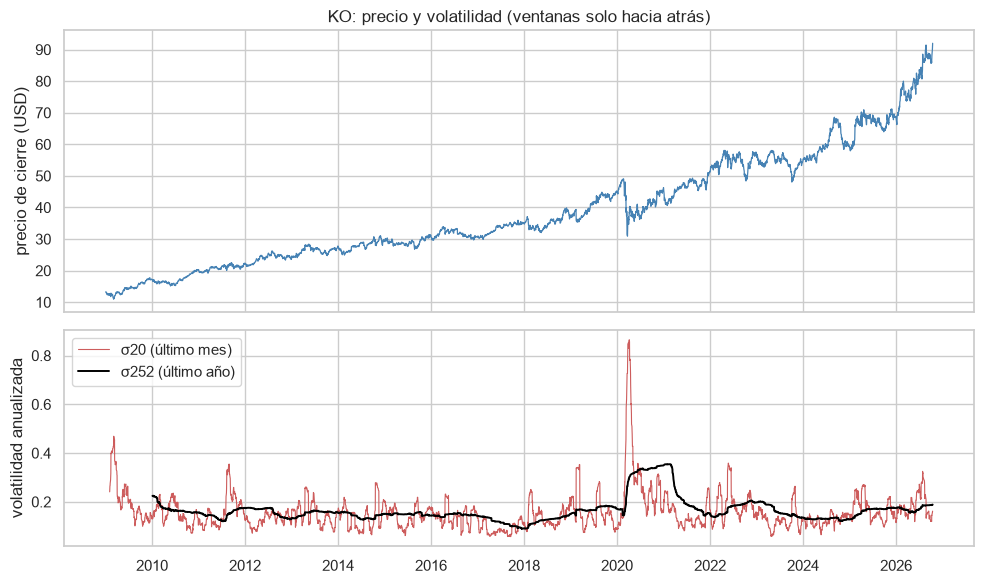

KO: σ252 anualizada entre 9.0% y 35.5% (mediana 15.4%); σ20 anualizada llegó a 86.5% el 2020-04-06


In [4]:
# Figura: precio de KO y las dos volatilidades (σ20 y σ252, anualizadas solo para leerlas: × √252)
g = panel[panel.ticker == TICKER_EJ].set_index("fecha")
fig, ax = plt.subplots(2, 1, figsize=(10, 6), sharex=True, gridspec_kw={"height_ratios": [1.3, 1]})
ax[0].plot(g.index, g["close"], color="steelblue", lw=0.9); ax[0].set_ylabel("precio de cierre (USD)")
ax[0].set_title(f"{TICKER_EJ}: precio y volatilidad (ventanas solo hacia atrás)")
ax[1].plot(g.index, g["sigma20"] * np.sqrt(252), color="indianred", lw=0.8, label="σ20 (último mes)")
ax[1].plot(g.index, g["sigma252"] * np.sqrt(252), color="black", lw=1.4, label="σ252 (último año)")
ax[1].set_ylabel("volatilidad anualizada"); ax[1].legend(loc="upper left")
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS_E2 / "nb05_variables_ko.png", dpi=130); plt.show()
v = g.dropna()
print(f"{TICKER_EJ}: σ252 anualizada entre {v.sigma252.min()*np.sqrt(252):.1%} y {v.sigma252.max()*np.sqrt(252):.1%} (mediana {v.sigma252.median()*np.sqrt(252):.1%}); "
      f"σ20 anualizada llegó a {v.sigma20.max()*np.sqrt(252):.1%} el {v.sigma20.idxmax().date()}")

**Lectura.** El panel conserva las 93 954 filas y pasa de 4 a 8 columnas. Sus vacíos no son errores: `r` y `abs_r` tienen 21 (el primer día de cada empresa no tiene día anterior), `sigma20` tiene 420 (20 por empresa) y `sigma252` y el cociente tienen 5 292 (252 por empresa). La σ252 diaria va de 0,0056 a 0,0446 (mediana 0,0120, unos 19 % anual) y el cociente σ20/σ252 tiene mediana 0,893 y llega a 3,41: un mes 3,4 veces más agitado que el año. En la figura, la σ252 anualizada de KO oscila entre 9,0 % y 35,5 % (mediana 15,4 %), mientras la σ20 es mucho más nerviosa y llegó a 86,5 % el 2020-04-06, en plena crisis del COVID. Por eso el cociente informa: mide cuánto se aparta el momento de la volatilidad habitual de la empresa.

## 3. Verificación de "sin look-ahead" (celda ejecutada)

Prueba: se recalcula el panel de KO **solo con los precios hasta `2015-12-31`** y se compara con el panel calculado con todos los precios. Si alguna variable de una fecha ≤ 2015-12-31 usara un precio posterior, el valor cambiaría al cortar. Como control negativo (para mostrar que la prueba **sí puede fallar**) se repite con una σ252 mal construida, centrada (`center=True`, mira hacia adelante), que debe dar distinto.

In [5]:
px_ko = precios[precios.ticker == TICKER_EJ]
completo = cm.construir_panel_diario(px_ko).set_index("fecha")
cortado = cm.construir_panel_diario(px_ko[px_ko.fecha <= CORTE_LOOKAHEAD]).set_index("fecha")
comp_ant = completo.loc[cortado.index]                                    # mismas fechas (≤ corte) del panel completo
iguales = {v: bool(np.allclose(comp_ant[v], cortado[v], equal_nan=True)) for v in VARS_PANEL}
print(f"fechas comparadas: {fm(len(cortado))} (hasta {cortado.index.max().date()})")
for v, ok in iguales.items():
    print(f"  {v:<18} coincide con el panel completo: {ok}")
lookahead_ok = all(iguales.values())

# Control negativo: σ252 centrada (usa 126 sesiones futuras) cambia al cortar → la prueba detecta el look-ahead
def sigma_centrada(p):
    r = np.log(p.set_index("fecha")["close"]).diff()
    return r.rolling(cm.SIGMA_VENTANA_D, min_periods=cm.SIGMA_VENTANA_D, center=True).std(ddof=1)
sc_comp = sigma_centrada(px_ko).loc[cortado.index]
sc_cort = sigma_centrada(px_ko[px_ko.fecha <= CORTE_LOOKAHEAD])
n_dif = int((~np.isclose(sc_comp, sc_cort, equal_nan=True)).sum())
print(f"\ncontrol negativo (σ252 centrada): {n_dif} fechas ≤ corte cambian al cortar → la prueba detecta el look-ahead: {n_dif > 0}")
print(f"\nlookahead_ok = {lookahead_ok}")
assert lookahead_ok and n_dif > 0
res["lookahead_ok"] = bool(lookahead_ok)
res["lookahead_control_negativo_fechas_distintas"] = n_dif

fechas comparadas: 1 762 (hasta 2015-12-31)
  r                  coincide con el panel completo: True
  abs_r              coincide con el panel completo: True
  sigma20            coincide con el panel completo: True
  sigma252           coincide con el panel completo: True
  sigma20_sigma252   coincide con el panel completo: True

control negativo (σ252 centrada): 125 fechas ≤ corte cambian al cortar → la prueba detecta el look-ahead: True

lookahead_ok = True


**Lectura.** Las 5 variables del panel de KO coinciden con el panel completo en las 1 762 fechas hasta 2015-12-31 (`lookahead_ok = True`): ninguna usa un precio posterior a su fecha. La prueba puede fallar: con la σ252 centrada, 125 de esas fechas cambian al cortar los precios, así que un look-ahead de ese tipo se detectaría. Esta verificación es sobre KO; las demás empresas usan la misma función, aplicada con `groupby` por ticker.

## 4. Calentamiento y datos faltantes

Las primeras sesiones de cada empresa no tienen σ252: hacen falta 252 retornos para calcularla (y el primer retorno, que necesita dos precios). Esas filas **se descartan; no se imputan**. Imputar σ (con la media, con la del vecino, con ceros) inventaría una volatilidad que no se observó y, peor, un valor imputado con datos posteriores sería look-ahead. Se cuenta también si hay **huecos de precio** (sesiones del calendario sin dato) dentro de las ventanas: un hueco dentro de las 60 sesiones futuras deja la etiqueta vacía (censura, por diseño de `etiqueta_entrada`).

In [6]:
calendario = np.sort(precios.fecha.unique())
por_t = panel.groupby("ticker").agg(sesiones=("close", "size"), sin_sigma252=("sigma252", lambda s: int(s.isna().sum())),
                                    primera_sigma252=("sigma252", lambda s: panel.loc[s.dropna().index[0], "fecha"].date()))
por_t["huecos_vs_calendario"] = len(calendario) - por_t["sesiones"]          # sesiones del calendario común que el ticker no tiene
por_t["precios_vacios"] = precios.groupby("ticker")["close"].apply(lambda s: int(s.isna().sum()))
print(f"calendario común: {fm(len(calendario))} sesiones ({pd.Timestamp(calendario[0]).date()} a {pd.Timestamp(calendario[-1]).date()})")
print(por_t.to_string())
n_calent = int(por_t.sin_sigma252.sum())
print(f"\nfilas descartadas por calentamiento: {fm(n_calent)} en total ({por_t.sin_sigma252.min()}–{por_t.sin_sigma252.max()} por empresa)")
print(f"huecos de precio dentro del calendario: {int(por_t.huecos_vs_calendario.sum())}; precios vacíos: {int(por_t.precios_vacios.sum())}")
res["n_calentamiento"] = {"total": n_calent, "por_ticker": {t: int(v) for t, v in por_t.sin_sigma252.items()}}
res["huecos_de_precio"] = int(por_t.huecos_vs_calendario.sum())

calendario común: 4 474 sesiones (2009-01-02 a 2026-10-15)
        sesiones  sin_sigma252 primera_sigma252  huecos_vs_calendario  precios_vacios
ticker                                                                               
ADM         4474           252       2010-01-04                     0               0
CAG         4474           252       2010-01-04                     0               0
CHD         4474           252       2010-01-04                     0               0
CL          4474           252       2010-01-04                     0               0
CLX         4474           252       2010-01-04                     0               0
COST        4474           252       2010-01-04                     0               0
GIS         4474           252       2010-01-04                     0               0
HSY         4474           252       2010-01-04                     0               0
KMB         4474           252       2010-01-04                     0            

**Lectura.** Las 21 empresas tienen las 4 474 sesiones del calendario común (0 huecos, 0 precios vacíos), de modo que el calentamiento es idéntico: 252 filas por empresa, 5 292 en total (5,6 % de las 93 954), y la primera σ252 aparece el 2010-01-04 para todas. Se descartan en vez de imputarse porque cualquier relleno inventaría una volatilidad no observada. Sin huecos de precio, las únicas etiquetas vacías serán las del final de la serie (§5.2).

## 5. Etiqueta con N = 60 y la rejilla de k, y censura

**Qué se predice.** Para una empresa, un día t y un número k: se miran las próximas N = 60 sesiones (un trimestre bursátil). La barrera **inferior** está a `precio_t · exp(−k · σ252 · √60)` (una caída de k "desviaciones del horizonte") y la **superior** a `precio_t · exp(+K_SUP · σ252 · √60)` con `K_SUP = 1`. La etiqueta es `y = 1` si el precio toca primero la inferior (la entrada del usuario habría ocurrido) y `y = 0` si toca primero la superior o se agotan las 60 sesiones. La tabla del modelo **apila** la etiqueta para `k ∈ {0,5; 1; 1,5; 2}`, de modo que k entra al modelo como un número más (así un nivel de entrada del usuario más lejano o más cercano se traduce a otro k). **La rejilla de k mueve solo la barrera inferior**: la superior queda fija en `K_SUP = 1`, así que solo con k = 1 la etiqueta es la simétrica de la entrega 1 (§5.1).

**Censura.** Las últimas 60 sesiones de cada empresa no tienen las 60 sesiones futuras: su etiqueta es vacía (`censurada = True`) y se excluyen de todos los conjuntos; no se mezclan con las completas.

In [7]:
tabla = cm.tabla_modelo(panel)                      # panel + k, y, censurada; una fila por (fecha, ticker, k); ya sin calentamiento
print(f"tabla del modelo: {fm(tabla.shape[0])} filas × {tabla.shape[1]} columnas {list(tabla.columns)}")
print(f"  = {fm(panel.dropna(subset=['sigma252']).shape[0])} filas del panel con σ252 × {len(cm.K_GRID)} valores de k")

# Antes/después de la etiqueta para una fecha: una fila por k, con el precio de cada barrera y cómo se resolvió
g = panel[panel.ticker == TICKER_EJ].set_index("fecha", drop=False)
f0 = pd.Timestamp(FECHA_EJ_ETIQUETA)
filas = []
for k in cm.K_GRID:
    lab = cm.etiqueta_entrada(g["close"], g["sigma252"], k, cm.K_SUP, cm.N_DIAS).loc[f0]
    ancho = g.loc[f0, "sigma252"] * np.sqrt(cm.N_DIAS)
    filas.append({"k": k, "precio_t": g.loc[f0, "close"], "barrera_inf": g.loc[f0, "close"] * np.exp(-k * ancho),
                  "barrera_sup": g.loc[f0, "close"] * np.exp(cm.K_SUP * ancho), "resultado": lab["resultado"],
                  "sesiones": lab["sesiones"], "y": lab["etiqueta"]})
print(f"\n{TICKER_EJ} el {f0.date()}: σ252 = {g.loc[f0, 'sigma252']:.4f} diaria → ancho σ·√{cm.N_DIAS} = {g.loc[f0, 'sigma252'] * np.sqrt(cm.N_DIAS):.3f}")
print(pd.DataFrame(filas).to_string(index=False))
chk = tabla[(tabla.ticker == TICKER_EJ) & (tabla.fecha == f0)].set_index("k")["y"]
assert all(chk.loc[r["k"]] == r["y"] for r in filas), "la tabla debe coincidir con la etiqueta calculada directamente"

tabla del modelo: 354 648 filas × 11 columnas ['fecha', 'ticker', 'close', 'r', 'abs_r', 'sigma20', 'sigma252', 'sigma20_sigma252', 'k', 'y', 'censurada']
  = 88 662 filas del panel con σ252 × 4 valores de k



KO el 2018-01-17: σ252 = 0.0057 diaria → ancho σ·√60 = 0.044
     k  precio_t  barrera_inf  barrera_sup resultado  sesiones      y
0.5000   35.7951      35.0112      37.4159   entrada   13.0000 1.0000
1.0000   35.7951      34.2445      37.4159   entrada   14.0000 1.0000
1.5000   35.7951      33.4945      37.4159   entrada   16.0000 1.0000
2.0000   35.7951      32.7610      37.4159   entrada   46.0000 1.0000


**Lectura.** Para KO el 2018-01-17 (σ252 diaria 0,0057, ancho σ·√60 = 0,044) el precio es 35,80 y la barrera superior (37,42) no depende de k; la inferior baja de 35,01 con k = 0,5 a 32,76 con k = 2. En los cuatro k el precio tocó primero la barrera inferior (a las 13, 14, 16 y 46 sesiones), así que y = 1 en las cuatro filas: cuanto más lejos está la barrera, más tarda en tocarse. La tabla del modelo tiene 354 648 filas = 88 662 filas con σ252 × 4 valores de k y coincide con la etiqueta calculada directamente (la celda lo comprueba).

### 5.1 Consistencia con la entrega 1 (k = 1)

La barrera superior es `K_SUP = 1`, la misma de la entrega 1, así que para `k = 1` la etiqueta debe ser **exactamente** la del notebook 04 (`etiqueta_entrada` con `k_inf = k_sup = 1`, σ252 y N = 60). Dos comprobaciones: (a) las cifras que imprimió nb04 §4.3–4.4 (n = 47 544 filas y tasa de toque 0,1839, para fechas ≤ 2018-12-31, no censuradas y con σ252), que son una referencia **independiente** de este cálculo; (b) como apoyo (es circular porque usa la misma función), la comparación fila a fila con una llamada directa de un ticker.

In [8]:
s1 = tabla[(tabla.k == 1.0) & (~tabla.censurada) & (tabla.fecha <= FIN_NB04)]
n1, tasa1 = len(s1), float(s1.y.mean())
print(f"k = 1, fecha ≤ {FIN_NB04}, no censuradas: n = {fm(n1)}  tasa de toque = {tasa1:.4f}")
print(f"nb04 §4.3–4.4:                            n = {fm(N_NB04)}  tasa de toque = {TASA_NB04:.4f}")
ok_cifras = (n1 == N_NB04) and (round(tasa1, 4) == TASA_NB04)

# (b) apoyo: comparación fila a fila con una llamada directa para un ticker
gk = panel[panel.ticker == TICKER_EJ].set_index("fecha", drop=False)
directa = cm.etiqueta_entrada(gk["close"], gk["sigma252"], 1, 1, cm.N_DIAS)["etiqueta"]
de_tabla = tabla[(tabla.ticker == TICKER_EJ) & (tabla.k == 1.0)].set_index("fecha")["y"]
ok_fila = bool(np.array_equal(directa.loc[de_tabla.index].fillna(-1).to_numpy(), de_tabla.fillna(-1).to_numpy()))
print(f"\nfila a fila con cm.etiqueta_entrada(close, σ252, 1, 1, 60) de {TICKER_EJ}: {fm(len(de_tabla))} filas, idénticas: {ok_fila}")
etiqueta_consistente = bool(ok_cifras and ok_fila)
print(f"etiqueta_consistente_con_nb04 = {etiqueta_consistente}")
assert etiqueta_consistente
res["etiqueta_consistente_con_nb04"] = etiqueta_consistente
res["consistencia_nb04"] = {"n": n1, "tasa": round(tasa1, 4), "n_nb04": N_NB04, "tasa_nb04": TASA_NB04}

k = 1, fecha ≤ 2018-12-31, no censuradas: n = 47 544  tasa de toque = 0.1839
nb04 §4.3–4.4:                            n = 47 544  tasa de toque = 0.1839

fila a fila con cm.etiqueta_entrada(close, σ252, 1, 1, 60) de KO: 4 222 filas, idénticas: True
etiqueta_consistente_con_nb04 = True


**Lectura.** Con `k = 1` la tabla reproduce exactamente las cifras de nb04 (n = 47 544 y tasa de toque 0,1839, las dos independientes de este cálculo) y las 4 222 etiquetas de KO coinciden fila a fila con la llamada directa. Se concluye que la etiqueta de la entrega 2 es la misma de la entrega 1 con una rejilla de k encima: lo que ya se sabía de la etiqueta con k = 1 sigue valiendo. **Alcance de esa consistencia:** vale solo con k = 1. En la entrega 1, N = 60 se eligió exigiendo que la tasa de toque quedara entre 10 % y 40 % con k = 1; la rejilla de k (0,5; 1; 1,5; 2) se fijó después, por diseño, para que el nivel del usuario se traduzca a un k, y no se volvió a filtrar por esa tasa. Con k = 1,5 y 2 las tasas de toque quedan por debajo de ese rango (§8), una limitación declarada.

### 5.2 Filas censuradas: se cuentan aparte y se excluyen

In [9]:
cens = tabla[tabla.censurada]
por_tk = cens.groupby(["ticker", "k"]).size().unstack("k")
print(f"filas censuradas: {fm(len(cens))} de {fm(len(tabla))} ({len(cens)/len(tabla):.2%}); fechas {cens.fecha.min().date()} a {cens.fecha.max().date()}")
print("\npor k:", cens.groupby("k").size().to_dict())
print("por ticker (primeros 6; todas iguales):"); print(por_tk.head(6).to_string())
# ¿Son exactamente las últimas 60 sesiones de cada ticker? (si hubiera huecos de precio saldrían más)
ult60 = set(calendario[-cm.N_DIAS:])
solo_ult = all(set(cens[(cens.ticker == t) & (cens.k == 1.0)].fecha) == ult60 for t in cm.tickers())
print(f"\ncada ticker tiene censuradas exactamente las últimas {cm.N_DIAS} sesiones del calendario: {solo_ult}")
print(f"filas con y vacía y NO censurada (no debería haber): {int((tabla.y.isna() & ~tabla.censurada).sum())}")
res["n_censuradas"] = {"total": int(len(cens)), "por_k": {str(float(k)): int(n) for k, n in cens.groupby("k").size().items()},
                       "por_ticker": {t: int(n) for t, n in cens.groupby("ticker").size().items()}, "fecha_min": str(cens.fecha.min().date())}

filas censuradas: 5 040 de 354 648 (1.42%); fechas 2026-07-23 a 2026-10-15

por k: {0.5: 1260, 1.0: 1260, 1.5: 1260, 2.0: 1260}
por ticker (primeros 6; todas iguales):
k       0.5000  1.0000  1.5000  2.0000
ticker                                
ADM         60      60      60      60
CAG         60      60      60      60
CHD         60      60      60      60
CL          60      60      60      60
CLX         60      60      60      60
COST        60      60      60      60

cada ticker tiene censuradas exactamente las últimas 60 sesiones del calendario: True
filas con y vacía y NO censurada (no debería haber): 0


**Lectura.** Hay 5 040 filas censuradas (1,42 % de la tabla): 60 sesiones × 21 empresas × 4 k, del 2026-07-23 al 2026-10-15; son exactamente las últimas 60 sesiones de cada empresa (ningún hueco de precio agrega más) y ninguna fila queda con `y` vacía sin estar marcada. No entran a ningún conjunto: su etiqueta sería "no tocó" solo por falta de tiempo, y tratarlas como 0 sesgaría la tasa de toque de la prueba hacia abajo.

## 6. Estandarización, codificación y submuestra

### 6.1 La partición se asigna antes de ajustar nada

`cm.asignar_conjunto` etiqueta cada fecha como entrenamiento (2009–2014; las filas con σ252 empiezan el 2010-01-04 por el calentamiento), validación (2015–2018), prueba (2019+) o brecha (las 60 sesiones anteriores a cada frontera; el notebook 06 la justifica y la verifica). Se llama sobre la tabla **completa**, antes de filtrar, porque la brecha se cuenta sobre el calendario que recibe. La función no marca las censuradas, que quedan como "prueba": aquí se filtran con `censurada == False` antes de cualquier conteo.

In [10]:
tabla["conjunto"] = cm.asignar_conjunto(tabla["fecha"])        # sobre la tabla completa, antes de filtrar
usables = tabla[(~tabla.censurada) & (tabla.conjunto != "brecha")]       # lo que alimenta a los modelos
print(tabla.groupby("conjunto").size().rename("filas (incluye censuradas en 'prueba')").to_frame().to_string())
print(f"\nfilas utilizables por conjunto (sin brecha ni censuradas): {usables.groupby('conjunto').size().to_dict()}")

               filas (incluye censuradas en 'prueba')
conjunto                                             
brecha                                          10080
entrenamiento                                  100632
prueba                                         164472
validacion                                      79464

filas utilizables por conjunto (sin brecha ni censuradas): {'entrenamiento': 100632, 'prueba': 159432, 'validacion': 79464}


### 6.2 Estandarización (z-score) ajustada solo con el entrenamiento

El SVM es sensible a la escala (`sigma252` ronda 0,01 y `k` va de 0,5 a 2), así que las variables se estandarizan: `z = (x − media) / desviación`. **La media y la desviación se calculan solo con las filas de entrenamiento** y se **reutilizan** en validación y prueba. Si se ajustaran con todos los datos, la escala llevaría información de 2015 en adelante al entrenamiento (fuga). El escalado real vive en el pipeline del notebook 07; aquí se demuestra con cifras.

**Por qué también se escala `k`.** `k` no es una medida de mercado, pero el SVM calcula distancias entre filas: una variable con rango 0,5–2 pesaría mucho más que `sigma252` (≈ 0,01) si las cuatro no se llevaran a una escala comparable.

**Codificación.** No hay variables categóricas: el ticker **no** es una variable del modelo (el modelo no sabe de qué empresa es la fila) y `k` entra como número. Por eso no hace falta ninguna codificación (ni one-hot ni etiquetas numéricas).

In [11]:
ent = usables[usables.conjunto == "entrenamiento"]
sc = StandardScaler().fit(ent[cm.VARIABLES])                              # ajuste SOLO con entrenamiento
params = pd.DataFrame({"media_entrenamiento": sc.mean_, "desv_entrenamiento": sc.scale_}, index=cm.VARIABLES)
todo = StandardScaler().fit(usables[cm.VARIABLES])                        # lo que NO se hace: ajustar con todo
params["media_si_se_ajustara_con_todo"] = todo.mean_
print(f"filas de entrenamiento usadas para ajustar: {fm(len(ent))}\n"); print(params.to_string())
z = {c: pd.DataFrame(sc.transform(usables.loc[usables.conjunto == c, cm.VARIABLES]), columns=cm.VARIABLES)
     for c in ["entrenamiento", "validacion", "prueba"]}
print("\nmedia de z por conjunto (con los parámetros del entrenamiento):")
print(pd.DataFrame({c: d.mean() for c, d in z.items()}).T.to_string())
print("\ndesviación de z por conjunto:")
print(pd.DataFrame({c: d.std() for c, d in z.items()}).T.to_string())

filas de entrenamiento usadas para ajustar: 100 632

                  media_entrenamiento  desv_entrenamiento  media_si_se_ajustara_con_todo
abs_r                          0.0079              0.0084                         0.0093
sigma20_sigma252               0.9246              0.3150                         0.9498
sigma252                       0.0115              0.0036                         0.0131
k                              1.2500              0.5590                         1.2500

media de z por conjunto (con los parámetros del entrenamiento):
                abs_r  sigma20_sigma252  sigma252       k
entrenamiento -0.0000            0.0000    0.0000 -0.0000
validacion     0.0483            0.1884    0.0062 -0.0000
prueba         0.3061            0.0765    0.9383 -0.0000

desviación de z por conjunto:
               abs_r  sigma20_sigma252  sigma252      k
entrenamiento 1.0000            1.0000    1.0000 1.0000
validacion    1.0665            1.1068    0.7877 1.0000
prueba

**Lectura.** Con los parámetros del entrenamiento (σ252: media 0,0115, desviación 0,0036) el z tiene media 0 y desviación 1 en entrenamiento por construcción, y no en validación ni prueba, lo cual es correcto: en la prueba el z medio de σ252 es 0,94 y su desviación 1,28 (2019+ incluye el COVID y 2022, más agitados que 2009–2014), mientras que en validación el z medio es 0,006 con menor dispersión (0,79). Si la escala se hubiera ajustado con todos los datos, la media de σ252 sería 0,0131 en vez de 0,0115 y el entrenamiento habría "visto" parte del futuro. `k` queda con media 1,25 y desviación 0,559 en los tres conjuntos porque la rejilla es la misma en todos.

### 6.3 Submuestra de entrenamiento

Las filas de días vecinos casi no se diferencian: la etiqueta de t y la de t+1 comparten 59 de sus 60 sesiones futuras. Entrenar con todas las filas hace lento el SVM RBF (su costo crece más que proporcionalmente con las filas) y sobrerrepresenta unos pocos episodios. `cm.submuestra` conserva **una fila cada `PASO_SUBMUESTRA = 5` sesiones por empresa y por k**, de forma determinista. Solo se aplica al **entrenamiento**; validación y prueba se evalúan con todas sus filas.

In [12]:
sub = cm.submuestra(ent)
print(f"entrenamiento: antes {fm(len(ent))} filas → después {fm(len(sub))} (1 de cada {cm.PASO_SUBMUESTRA}: {len(sub)/len(ent):.3f})")
comp = pd.DataFrame({"filas_antes": ent.groupby("k").size(), "filas_despues": sub.groupby("k").size(),
                     "tasa_antes": ent.groupby("k").y.mean(), "tasa_despues": sub.groupby("k").y.mean()})
comp["dif_tasa_pp"] = (comp.tasa_despues - comp.tasa_antes) * 100
print(comp.to_string())
tk = sub[(sub.ticker == TICKER_EJ) & (sub.k == 1.0)].fecha
cal_pos = pd.Series(np.arange(len(calendario)), index=pd.DatetimeIndex(calendario))
sep = cal_pos.loc[tk].diff().dropna()
print(f"\n{TICKER_EJ}, k = 1: {len(tk)} fechas; separación en sesiones: mínima {int(sep.min())}, mediana {int(sep.median())}, máxima {int(sep.max())}")
print(f"filas por empresa y k tras la submuestra: mínimo {sub.groupby(['ticker','k']).size().min()}, máximo {sub.groupby(['ticker','k']).size().max()}")
res["submuestra"] = {"filas_antes": int(len(ent)), "filas_despues": int(len(sub)), "paso": cm.PASO_SUBMUESTRA}

entrenamiento: antes 100 632 filas → después 20 160 (1 de cada 5: 0.200)
        filas_antes  filas_despues  tasa_antes  tasa_despues  dif_tasa_pp
k                                                                        
0.5000        25158           5040      0.3858        0.3823      -0.3500
1.0000        25158           5040      0.1404        0.1395      -0.0869
1.5000        25158           5040      0.0397        0.0405       0.0727
2.0000        25158           5040      0.0081        0.0085       0.0383

KO, k = 1: 240 fechas; separación en sesiones: mínima 5, mediana 5, máxima 5
filas por empresa y k tras la submuestra: mínimo 240, máximo 240


**Lectura.** La submuestra deja 20 160 de las 100 632 filas de entrenamiento (una de cada cinco: 5 040 por k, 240 por empresa y k), con separación exacta de 5 sesiones. Conserva la tasa de toque: cambia −0,35 pp con k = 0,5, −0,09 pp con k = 1, +0,07 pp con k = 1,5 y +0,04 pp con k = 2. El solapamiento se reduce, no se elimina: dos filas consecutivas de la submuestra aún comparten 55 de sus 60 sesiones futuras. Por eso las decisiones de los notebooks siguientes usan bootstrap por bloques de fechas, no el p-value clásico.

### 6.4 Resumen: transformaciones del enunciado, si se aplican y dónde está la evidencia

| Transformación | ¿Se aplica? | Por qué | Evidencia |
|---|---|---|---|
| Nuevas características | **Sí** | σ20, σ252, el cociente σ20/σ252 y \|r\| resumen cuánto se mueve el precio, solo con datos hacia atrás | §2 (antes/después y muestra) y §3 (sin look-ahead, con control negativo) |
| Codificación de categóricas | **No aplica** | no hay variables categóricas: el ticker no es variable y `k` entra como número | §6.2 y fila "Procesabilidad" de §9 |
| Normalización (min-max) | **No se usa** | reescala con el mínimo y el máximo del entrenamiento; en la volatilidad esos extremos son poco representativos (σ252 de 0,0056 a 0,0446 en todo el panel, mediana 0,0120) y la prueba, más agitada, saldría del rango [0, 1]. Se usa el z-score | §2 (rango de σ252) y notebook 06 §5 (máximo de σ252 de 0,0334 en entrenamiento y 0,0446 en prueba) |
| Estandarización (z-score) | **Sí** | el SVM calcula distancias y es sensible a la escala; la media y la desviación salen solo del entrenamiento | §6.2 (parámetros del entrenamiento y media de z por conjunto); el ajuste real vive en el pipeline del notebook 07 |
| Imputación de vacíos | **No** | los únicos vacíos son los del calentamiento y los de la censura; rellenarlos inventaría una volatilidad no observada | §4 (0 huecos de precio) y §9 ("sin vacíos en los datos preparados") |
| Descarte del calentamiento | **Sí** | sin 252 retornos no hay σ252: 252 filas por empresa, 5 292 en total | §4 y la conciliación de §8 |
| Censura de la etiqueta | **Sí** | las últimas 60 sesiones no tienen futuro completo: se cuentan aparte y no entran a ningún conjunto | §5.2 |
| Submuestra | **Sí, solo en entrenamiento** | una fila cada 5 sesiones reduce el solapamiento y hace entrenable al SVM RBF | §6.3 |

**Por qué z-score y no min-max.** El z-score resta la media y divide por la desviación del entrenamiento: un valor extremo desplaza menos al resto de las filas que cuando se usa el máximo como tope, y los valores de la prueba pueden salir del rango del entrenamiento sin romper la escala (el z de la σ252 en la prueba es 0,94 en promedio, §6.2). Con min-max, un máximo de entrenamiento de 0,0334 dejaría los 0,0446 de la prueba por encima de 1.


## 7. Rama fundamental: EPS TTM con su fecha `filed`

La rama fundamental (múltiplos y percentiles) **reutiliza la entrega 1**: la construcción de `ratios_ttm` está en [nb01](01_recoleccion.ipynb) y su calidad en [nb02](02_calidad.ipynb); los múltiplos semanales y el ajuste por splits son las mismas funciones del notebook 04, hoy en `comunes.py`. Aquí se muestra el punto de preparación que importa: **el P/E de cada semana usa solo el EPS TTM ya publicado** (`filed_eps_ttm` ≤ fecha de la semana), y los vacíos (EPS inexistente, EPS ≤ 0 o dato rancio) quedan vacíos, no se rellenan. Tres casos: **KO** (cobertura completa), **HSY** (su EPS TTM existe solo hasta 2015-12-31, 25 de 69 trimestres) y **STZ** (sin ningún EPS TTM). Un dato incompleto se reporta y no rompe el flujo: el producto avisa "sin P/E" para esa empresa.

In [13]:
sem_sd = cm.cargar_snapshot("precios_semanales_sd"); sem_sd["fecha"] = sem_sd["fecha"].astype("datetime64[ns]")
ttm = cm.cargar_snapshot("ratios_ttm")
for c in ttm.columns:
    if str(ttm[c].dtype).startswith("datetime64"):
        ttm[c] = ttm[c].astype("datetime64[ns]")
splits_all = cm.cargar_snapshot("splits"); splits_all["fecha"] = splits_all["fecha"].astype("datetime64[ns]")

EJEMPLOS_FUND = ["KO", "HSY", "STZ"]
mult, filas = {}, []
for t in EJEMPLOS_FUND:
    sd_t, r_t, sp_t = sem_sd[sem_sd.ticker == t], ttm[ttm.ticker == t], splits_all[splits_all.ticker == t]
    r_adj = cm.ajustar_por_splits(r_t, sp_t)
    m = cm.multiplos_semanales(sd_t, r_adj)
    # Verificación de "sin look-ahead": EPS publicado más reciente con filed ≤ fecha de la semana
    pub = (r_adj[["filed_eps_ttm", "eps_ttm", "end"]].dropna(subset=["filed_eps_ttm"]).sort_values("filed_eps_ttm"))
    cmp_ = pd.merge_asof(m[["fecha"]], pub, left_on="fecha", right_on="filed_eps_ttm", direction="backward")
    m["filed_eps_ttm"] = cmp_["filed_eps_ttm"].to_numpy()
    con_eps = m.eps_ttm.notna()
    dias = (m.loc[con_eps, "fecha"] - m.loc[con_eps, "filed_eps_ttm"]).dt.days
    mult[t] = m
    filas.append({"ticker": t, "semanas": len(m), "trimestres_con_EPS": int(r_t.eps_ttm.notna().sum()), "trimestres": len(r_t),
                  "semanas_con_PE": int(m.pe.notna().sum()),
                  "sin_EPS_aun": int((~con_eps & m.filed_eps_ttm.isna()).sum()),
                  "EPS_rancio": int((~con_eps & m.filed_eps_ttm.notna()).sum()),
                  "EPS_<=0": int((m.eps_ttm <= 0).sum()),
                  "ultima_semana_PE": m.loc[m.pe.notna(), "fecha"].max(),
                  "filed_posterior_a_la_semana": int((dias < 0).sum())})
print(pd.DataFrame(filas).to_string(index=False))
assert all(f["filed_posterior_a_la_semana"] == 0 for f in filas)
print("\n3 filas de muestra por empresa (la primera y la última semana con P/E, y la última semana):")
for t in EJEMPLOS_FUND:
    m = mult[t]; ok = m[m.pe.notna()]
    print(f"--- {t}"); print((pd.concat([ok.head(1), ok.tail(1), m.tail(1)])[["fecha", "close", "eps_ttm", "filed_eps_ttm", "pe"]]).to_string(index=False))
res["rama_fundamental"] = {f["ticker"]: {k: (str(v.date()) if hasattr(v, "date") else v) for k, v in f.items() if k != "ticker"} for f in filas}

ticker  semanas  trimestres_con_EPS  trimestres  semanas_con_PE  sin_EPS_aun  EPS_rancio  EPS_<=0 ultima_semana_PE  filed_posterior_a_la_semana
    KO      928                  66          67             833           95           0        0       2026-10-12                            0
   HSY      928                  25          69             372           71         485        0       2017-06-26                            0
   STZ      928                   0          65               0          928           0        0              NaT                            0

3 filas de muestra por empresa (la primera y la última semana con P/E, y la última semana):
--- KO
     fecha   close  eps_ttm filed_eps_ttm      pe
2010-11-01 31.2900   1.6226    2010-10-29 19.2833
2026-10-12 92.0000   3.1759    2026-04-30 28.9678
2026-10-12 92.0000   3.1759    2026-04-30 28.9678
--- HSY
     fecha    close  eps_ttm filed_eps_ttm      pe
2010-05-17  46.5600   2.2108    2010-05-12 21.0601
2017-06-26 107

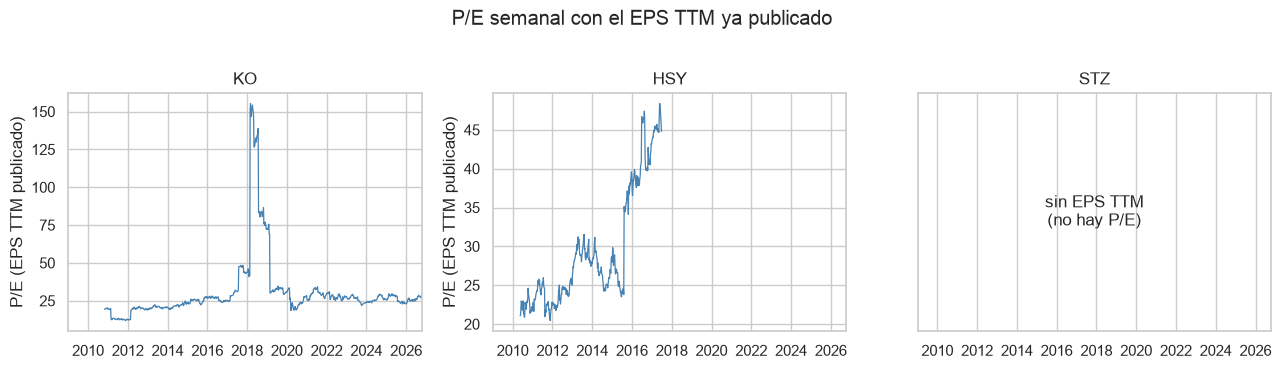

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=False)
for ax, t in zip(axes, EJEMPLOS_FUND):
    m = mult[t]
    if m.pe.notna().any():
        ax.plot(m.fecha, m.pe, lw=0.9, color="steelblue"); ax.set_ylabel("P/E (EPS TTM publicado)")
    else:
        ax.text(0.5, 0.5, "sin EPS TTM\n(no hay P/E)", ha="center", va="center", transform=ax.transAxes, fontsize=12); ax.set_yticks([])
    ax.set_xlim(m.fecha.min(), m.fecha.max()); ax.set_title(t)
plt.suptitle("P/E semanal con el EPS TTM ya publicado", y=1.02); plt.tight_layout()
fig.savefig(cm.DIR_ASSETS_E2 / "nb05_pe_ejemplos.png", dpi=130, bbox_inches="tight"); plt.show()

**Lectura.** KO tiene P/E en 833 de 928 semanas: las 95 vacías son las primeras, antes de que se publique el primer EPS TTM (el primer P/E es del 2010-11-01), y no hay semanas por EPS ≤ 0 ni rancio. HSY tiene P/E en 372 semanas, hasta el 2017-06-26: su último EPS TTM se publicó el 2016-02-26 (cierre de 2015-12-31) y pasados 548 días el dato se considera rancio, lo que deja 485 semanas vacías, más 71 al comienzo. STZ no tiene ningún EPS TTM (0 de 928 semanas). En las tres empresas el EPS usado se publicó siempre antes de la semana (0 violaciones de `filed`) y nada se rellena: HSY y STZ aparecen como vacíos en la figura, el flujo no se rompe y el producto debe mostrar "sin P/E" para esas empresas (qué otros múltiplos de la rama fundamental, como el P/B, se leen en su lugar no se evalúa en este notebook). El pico de KO (P/E de 155 en la semana del 2018-03-05) es un dato real, no un error: el EPS TTM publicado cayó a 0,289 y el P/E se dispara; es el caso que motivó el P/E normalizado (EPS promedio de 3 años) de la entrega 1.

## 8. Balance de la etiqueta por conjunto y datos preparados

Tasa de toque (proporción de filas con `y = 1`) por conjunto y por k, con el número de filas de cada celda. Los criterios para juzgar si cada conjunto se parece al total se fijan y se miden en el notebook 06; aquí se deja el balance y la conciliación de filas.

In [15]:
bal = usables.groupby(["conjunto", "k"]).y.agg(tasa="mean", filas="size").reset_index()
orden = ["entrenamiento", "validacion", "prueba"]
print("tasa de toque por conjunto × k:"); print(bal.pivot(index="conjunto", columns="k", values="tasa").loc[orden].to_string())
print("\nfilas por conjunto × k:"); print(bal.pivot(index="conjunto", columns="k", values="filas").loc[orden].to_string())
brecha = tabla[(tabla.conjunto == "brecha")]
b1_, b2_ = brecha[brecha.fecha < cm.INICIO_VALIDACION], brecha[brecha.fecha >= cm.INICIO_VALIDACION]
print(f"\nbrecha (descartada): {fm(len(brecha))} filas = {brecha.fecha.nunique()} sesiones × 21 empresas × {len(cm.K_GRID)} k; "
      f"antes de validación {b1_.fecha.min().date()}–{b1_.fecha.max().date()}, antes de la prueba {b2_.fecha.min().date()}–{b2_.fecha.max().date()}")

# Conciliación: todas las filas posibles = utilizables + brecha + censuradas + calentamiento
posibles = len(precios) * len(cm.K_GRID)
partes = {"utilizables": len(usables), "brecha": len(brecha), "censuradas": int(tabla.censurada.sum()), "calentamiento": n_calent * len(cm.K_GRID)}
print(f"\nconciliación: {fm(len(precios))} filas de precio × {len(cm.K_GRID)} k = {fm(posibles)}")
for k_, v in partes.items(): print(f"  {k_:<14}{v:>9,}")
print(f"  suma         {sum(partes.values()):>9,}  → cuadra: {sum(partes.values()) == posibles}")
assert sum(partes.values()) == posibles
res["balance_por_conjunto"] = {c: {str(float(k)): {"tasa": float(r.tasa), "filas": int(r.filas)}
                                   for k, r in bal[bal.conjunto == c].set_index("k").iterrows()} for c in orden}
res["conciliacion_filas"] = {**{k_: int(v) for k_, v in partes.items()}, "total": int(posibles)}

tasa de toque por conjunto × k:
k              0.5000  1.0000  1.5000  2.0000
conjunto                                     
entrenamiento  0.3858  0.1404  0.0397  0.0081
validacion     0.4762  0.2236  0.0928  0.0359
prueba         0.4578  0.2057  0.0926  0.0478

filas por conjunto × k:
k              0.5000  1.0000  1.5000  2.0000
conjunto                                     
entrenamiento   25158   25158   25158   25158
validacion      19866   19866   19866   19866
prueba          39858   39858   39858   39858

brecha (descartada): 10 080 filas = 120 sesiones × 21 empresas × 4 k; antes de validación 2014-10-07–2014-12-31, antes de la prueba 2018-10-04–2018-12-31

conciliación: 93 954 filas de precio × 4 k = 375 816
  utilizables     339,528
  brecha           10,080
  censuradas        5,040
  calentamiento    21,168
  suma           375,816  → cuadra: True


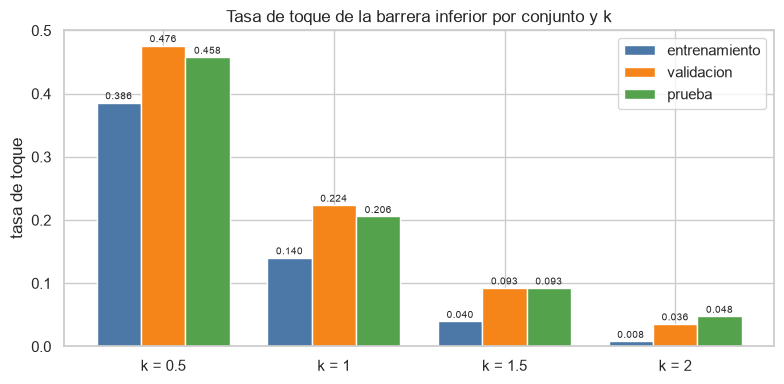

In [16]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(cm.K_GRID)); w = 0.26
for i, (c, col) in enumerate(zip(orden, ["#4c78a8", "#f58518", "#54a24b"])):
    t = bal[bal.conjunto == c].sort_values("k").tasa.to_numpy()
    b = ax.bar(x + (i - 1) * w, t, w, label=c, color=col)
    ax.bar_label(b, labels=[f"{v:.3f}" for v in t], fontsize=7, padding=1)
ax.set_xticks(x); ax.set_xticklabels([f"k = {k:g}" for k in cm.K_GRID]); ax.set_ylabel("tasa de toque")
ax.set_title("Tasa de toque de la barrera inferior por conjunto y k"); ax.legend()
plt.tight_layout(); fig.savefig(cm.DIR_ASSETS_E2 / "nb05_balance_conjuntos.png", dpi=130); plt.show()

**Lectura.** La tasa de toque baja al alejar la barrera en los tres conjuntos: entrenamiento 0,386 / 0,140 / 0,040 / 0,008 para k = 0,5 / 1 / 1,5 / 2, validación 0,476 / 0,224 / 0,093 / 0,036 y prueba 0,458 / 0,206 / 0,093 / 0,048. El entrenamiento es el más tranquilo: su tasa es menor que la de validación y la de prueba en los cuatro k (con k = 2, 0,8 % frente a 3,6 % y 4,8 %), de modo que el modelo aprenderá de una época con pocos movimientos extremos. El notebook 06 mide si esa diferencia viola los criterios de conservación. **Frente al rango 10–40 % con que la entrega 1 eligió N (con k = 1):** con k = 1 los tres conjuntos quedan dentro (0,140; 0,224 y 0,206), pero con k = 1,5 y 2 las tasas están por debajo de 10 % en los tres conjuntos (de 0,008 a 0,093), y con k = 0,5 la validación (0,476) y la prueba (0,458) superan el 40 %. Es decir, los k extremos tienen pocos toques (k = 1,5 y 2) o muchos (k = 0,5), y las métricas por k de los notebooks 07 y 08 se apoyan en menos ejemplos positivos o negativos de los que tuvo el k = 1 de la entrega 1. Las filas por conjunto y k son 25 158 (entrenamiento), 19 866 (validación) y 39 858 (prueba); la brecha descarta 10 080 (120 sesiones × 21 empresas × 4 k) y la conciliación cuadra: 339 528 + 10 080 + 5 040 + 21 168 = 375 816.

### 8.1 Datos preparados

La tabla que consumen los notebooks 06 a 08 (se copia en la sección 5 del reporte): una fila por (fecha, empresa, k), con las variables, la etiqueta `y` y el conjunto.

In [17]:
COLS_PREP = ["fecha", "ticker", "k", "abs_r", "sigma20_sigma252", "sigma252", "y", "conjunto"]
datos = usables[COLS_PREP]
print(f"tabla completa del modelo (con brecha y censuradas): {tabla.shape}")
print(f"datos preparados (sin brecha ni censuradas):          {datos.shape}")
muestra = datos.sample(N_MUESTRA, random_state=cm.SEMILLA).sort_values(["conjunto", "fecha", "ticker", "k"])
print("\n8 filas de muestra:"); print(muestra.to_string(index=False))
print(f"\nvacíos en los datos preparados: {int(datos.isna().sum().sum())}; y toma los valores {sorted(float(v) for v in datos.y.unique())}")
res["dimensiones"].update({"filas": int(tabla.shape[0]), "columnas": int(tabla.shape[1]), "tickers": int(tabla.ticker.nunique()),
                           "fecha_min": str(tabla.fecha.min().date()), "fecha_max": str(tabla.fecha.max().date()),
                           "filas_utilizables": int(datos.shape[0])})
res["filas_muestra"] = [{**{c: (str(r[c].date()) if c == "fecha" else r[c]) for c in COLS_PREP}} for _, r in muestra.iterrows()]
res["filas_muestra"] = json.loads(json.dumps(res["filas_muestra"], default=lambda o: o.item() if hasattr(o, "item") else str(o)))

tabla completa del modelo (con brecha y censuradas): (354648, 12)
datos preparados (sin brecha ni censuradas):          (339528, 8)

8 filas de muestra:
     fecha ticker      k  abs_r  sigma20_sigma252  sigma252      y      conjunto
2011-02-01    ADM 1.0000 0.0603            1.1278    0.0153 0.0000 entrenamiento
2011-08-18    CHD 2.0000 0.0230            2.1724    0.0131 0.0000 entrenamiento
2012-09-13     CL 2.0000 0.0185            0.9254    0.0100 0.0000 entrenamiento
2013-03-15    CAG 2.0000 0.0037            0.6785    0.0089 0.0000 entrenamiento
2019-08-21    GIS 1.0000 0.0017            0.7399    0.0145 0.0000        prueba
2021-12-27   COST 0.5000 0.0235            1.8770    0.0119 1.0000        prueba
2024-10-10    GIS 0.5000 0.0024            0.6494    0.0119 1.0000        prueba
2015-06-02    CLX 1.0000 0.0095            0.7148    0.0094 0.0000    validacion

vacíos en los datos preparados: 0; y toma los valores [0.0, 1.0]


**Lectura.** Los datos preparados son 339 528 filas × 8 columnas, sin vacíos y con `y` en {0, 1}; la tabla completa del modelo (354 648 × 12) conserva además la brecha y las censuradas para que el notebook 06 pueda verificarlas.

## 9. Calidad con las 9 dimensiones

La auditoría completa de las fuentes está en [nb02](02_calidad.ipynb); aquí solo se verifica lo que la preparación agrega y se remite al resto. Los nombres de las dimensiones son los de nb02 §0.

In [18]:
dim = pd.DataFrame([
    ("Completitud", "verificado aquí", f"calentamiento: {fm(n_calent)} filas sin σ252 (252 por empresa), descartadas y no imputadas; censura: {fm(len(cens))} filas sin etiqueta, aparte; huecos de precio: {int(por_t.huecos_vs_calendario.sum())}"),
    ("Consistencia", "verificado aquí", f"la etiqueta con k = 1 coincide con la del notebook 04 (n = {fm(n1)}, tasa {tasa1:.4f}); la conciliación de filas cuadra ({fm(posibles)})"),
    ("Conformidad", "ya en nb02", "formato de los precios (nb02 §1) y duraciones de los trimestres de EDGAR (nb02 §2b, chequeo 6)"),
    ("Relevancia", "ya en nb02", "qué datos sirven a cada pregunta: nb02 §6 y §8; del nb04 quedan solo las variables de magnitud"),
    ("Precisión", "ya en nb02", "plausibilidad, escala y verificación manual del EPS: nb02 §2b (chequeos 2, 4 y 9)"),
    ("Procesabilidad", "verificado aquí", f"sin vacíos en los datos preparados ({int(datos.isna().sum().sum())}); sin variables categóricas; z-score ajustado solo con entrenamiento"),
    ("Disponibilidad", "ya en nb02", "instantánea fechada y reproducible en data/snapshots (nb01); sin descargas en los notebooks siguientes"),
    ("Temporalidad", "verificado aquí", f"ventanas solo hacia atrás (lookahead_ok = {lookahead_ok}); P/E con el EPS publicado hasta la semana (filed ≤ fecha: 0 violaciones)"),
    ("Credibilidad", "ya en nb02", "yfinance, SEC EDGAR y Damodaran, fuentes gratuitas y declaradas; triangulación en nb02 §4"),
], columns=["Dimensión", "Estado", "Evidencia"])
print(dim.to_string(index=False, max_colwidth=150))
res["calidad_9_dimensiones"] = dim.to_dict("records")

     Dimensión          Estado                                                                                                                                         Evidencia
   Completitud verificado aquí calentamiento: 5 292 filas sin σ252 (252 por empresa), descartadas y no imputadas; censura: 5 040 filas sin etiqueta, aparte; huecos de precio: 0
  Consistencia verificado aquí                        la etiqueta con k = 1 coincide con la del notebook 04 (n = 47 544, tasa 0.1839); la conciliación de filas cuadra (375 816)
   Conformidad      ya en nb02                                                    formato de los precios (nb02 §1) y duraciones de los trimestres de EDGAR (nb02 §2b, chequeo 6)
    Relevancia      ya en nb02                                                    qué datos sirven a cada pregunta: nb02 §6 y §8; del nb04 quedan solo las variables de magnitud
     Precisión      ya en nb02                                                                 plausibilidad, escal

## 10. Diagrama de bloques

Resume el flujo completo: de las fuentes al dashboard, con las dos ramas (fundamental y simulación) que confluyen en la API. La figura la genera `scripts/diagramas.py`.

![Diagrama de bloques](../entregables/entrega_2/assets/diagrama_bloques.png)

**Lectura.** Las siete etapas del modelo técnico (fuentes, limpieza, variables, etiqueta, partición, estandarización y modelos) se preparan en este notebook (las etapas 3 y 4 y la asignación de la partición), se verifican en el 06 (partición y brecha) y se terminan en el 07: allí se ajusta de verdad la estandarización, dentro del pipeline, y se entrenan los modelos. En este notebook la estandarización solo se demuestra (§6.2). El diagrama marca además lo que no aplica: codificación e imputación (§6.4) y la submuestra del entrenamiento (una fila de cada 5). Las ramas fundamental y de simulación usan los mismos datos limpios y no pasan por la etiqueta; todas confluyen en la API, que entrega una lectura por cada uno de los 6 niveles del usuario.

## 11. Resultados guardados

In [19]:
destino = cm.DIR_RESULTADOS / "nb05.json"
cm.DIR_RESULTADOS.mkdir(parents=True, exist_ok=True)
destino.write_text(json.dumps(res, ensure_ascii=False, indent=1, default=str), encoding="utf-8")
print(f"Escrito: {destino.name} — claves: {list(res)}")

Escrito: nb05.json — claves: ['dimensiones', 'lookahead_ok', 'lookahead_control_negativo_fechas_distintas', 'n_calentamiento', 'huecos_de_precio', 'etiqueta_consistente_con_nb04', 'consistencia_nb04', 'n_censuradas', 'submuestra', 'rama_fundamental', 'balance_por_conjunto', 'conciliacion_filas', 'filas_muestra', 'calidad_9_dimensiones']
